# Contexta Research — 11 Model Evaluation

Built on SenseForge shared modules. Run sequentially from the repository root or notebooks directory. Missing data is explicitly skipped; no fabricated results.

In [2]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
DATA_ROOT=Path(os.environ.get('CONTEXTA_DATA_ROOT',str(ROOT/'datasets')))
ART=ROOT/'artifacts';ART.mkdir(exist_ok=True,parents=True)
print('Project:',ROOT,'Data:',DATA_ROOT)


Project: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge Data: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/datasets


## Common held-out WSD benchmark

In [4]:
from senseforge.research import read_jsonl
from senseforge.benchmark import evaluate,route
from senseforge.core import predict
from senseforge.inference import load_wsd
rows=read_jsonl(ART/'wsd_test.jsonl')
if not rows:print('SKIPPED: human-gold test partition missing')
else:
    results={method:evaluate(rows,lambda r,m=method:predict(r['text'],r['word'],method=m)) for method in ('dictionary','rule')}
    checkpoint=ART/'xlmr_supervised.pt';calibration=ART/'hybrid_threshold.json'
    if checkpoint.exists() and calibration.exists():
        neural=load_wsd(checkpoint,os.environ.get('CONTEXTA_MODEL','xlm-roberta-base'))
        threshold=json.loads(calibration.read_text())['threshold']
        results['neural']=evaluate(rows,lambda r:{'sense_id':neural(r)[0]})
        results['hybrid']=evaluate(rows,lambda r:route(r,neural,threshold))
    (ART/'benchmark.json').write_text(json.dumps(results,indent=2))
    print({k:{'n':v['n'],'macro_f1':v['macro_f1'],'accuracy':v['accuracy']} for k,v in results.items()})

SKIPPED: human-gold test partition missing


In [5]:
import json
import sys
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

ART = ROOT / "artifacts"
V2 = ART / "wsd_v2"
OUT = ART / "evaluation_v2"

OUT.mkdir(parents=True, exist_ok=True)

def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [
            json.loads(line)
            for line in f
            if line.strip()
        ]

train_rows = load_jsonl(V2 / "train.jsonl")
val_rows = load_jsonl(V2 / "validation.jsonl")
test_rows = load_jsonl(V2 / "test.jsonl")

SENSES = sorted({
    row["sense_id"]
    for row in train_rows
})

print("Training:", len(train_rows))
print("Validation:", len(val_rows))
print("Test:", len(test_rows))
print("Sense classes:", len(SENSES))

assert len(train_rows) == 506
assert len(val_rows) == 60
assert len(test_rows) == 62
assert len(SENSES) == 12

print("\nV2 evaluation dataset ready.")

Training: 506
Validation: 60
Test: 62
Sense classes: 12

V2 evaluation dataset ready.


In [6]:
def normalize(text):
    return " ".join(text.casefold().split())

splits = {
    "train": train_rows,
    "validation": val_rows,
    "test": test_rows
}

sentence_sets = {}

for name, rows in splits.items():
    texts = {
        normalize(row["text_en"])
        for row in rows
    }

    sentence_sets[name] = texts

    print(
        f"{name:12} "
        f"records={len(rows):3} "
        f"unique_sentences={len(texts):3}"
    )

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = sentence_sets[a] & sentence_sets[b]

    print(f"{a} vs {b}: {len(overlap)} overlaps")

    assert not overlap, (
        f"Sentence leakage detected: {a} vs {b}"
    )

print("\nExact sentence overlap audit passed.")

train        records=506 unique_sentences=485
validation   records= 60 unique_sentences= 53
test         records= 62 unique_sentences= 57
train vs validation: 0 overlaps
train vs test: 0 overlaps
validation vs test: 0 overlaps

Exact sentence overlap audit passed.


In [7]:
from senseforge.core import predict

def baseline_predict(row, method):
    text = row["text_en"]
    word = row["target_word"]

    start = int(row["target_char_start"])
    end = int(row["target_char_end"])

    assert 0 <= start < end <= len(text)

    try:
        result = predict(
            text, word, method=method
        )

    except ValueError as error:
        if "Target word not present" not in str(error):
            raise

        normalized_text = (
            text[:start]
            + word
            + text[end:]
        )

        result = predict(
            normalized_text,
            word,
            method=method
        )

    return result["sense_id"]


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

gold = [r["sense_id"] for r in test_rows]

baseline_results = {}

for method in ["dictionary", "rule"]:
    predictions = [
        baseline_predict(row, method)
        for row in test_rows
    ]

    baseline_results[method] = {
        "accuracy": float(
            accuracy_score(gold, predictions)
        ),
        "macro_precision": float(
            precision_score(
                gold, predictions,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                gold, predictions,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                gold, predictions,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        )
    }

    print(f"\n=== {method.upper()} ===")

    for metric, value in baseline_results[method].items():
        print(f"{metric}: {value:.4f}")

    print(classification_report(
        gold, predictions,
        labels=SENSES,
        zero_division=0
    ))


=== DICTIONARY ===
accuracy: 0.3871
macro_precision: 0.2175
macro_recall: 0.5000
macro_f1: 0.2923
              precision    recall  f1-score   support

      bank.1       0.50      1.00      0.67         3
      bank.2       0.00      0.00      0.00         3
  interest.1       0.43      1.00      0.60         3
  interest.2       0.00      0.00      0.00         4
     plant.1       0.18      1.00      0.30         3
     plant.2       0.00      0.00      0.00        14
     point.1       0.59      1.00      0.74        10
     point.2       0.00      0.00      0.00         7
     right.1       0.67      1.00      0.80         2
     right.2       0.00      0.00      0.00         1
     table.1       0.25      1.00      0.40         3
     table.2       0.00      0.00      0.00         9

    accuracy                           0.39        62
   macro avg       0.22      0.50      0.29        62
weighted avg       0.18      0.39      0.24        62


=== RULE ===
accuracy: 0.4677
mac

In [8]:
import gc
import inspect
import joblib
import numpy as np
import torch
import torch.nn as nn

from transformers import AutoModel, AutoTokenizer
from peft import PeftModel

SUP = ART / "wsd_v2_supervised"
ADV = ART / "wsd_v2_advanced"
LORA = ART / "wsd_v2_lora"
HYBRID = ART / "hybrid_v2"

DEVICE = torch.device("cpu")
MODEL_NAME = "xlm-roberta-base"
MAX_LENGTH = 64

# Load existing Notebook 08 embeddings.
# Do not recompute them using a different encoder.
cache_dir = SUP / "embedding_cache"
cache_path = cache_dir / "test_xlmr.npy"

assert cache_path.exists(), (
    f"Missing Notebook 08 test embeddings: {cache_path}"
)

X_test = np.load(cache_path).astype(np.float32)

assert X_test.shape == (len(test_rows), 768)

# Verify row ordering using the Notebook 08 manifest.
import hashlib

manifest = json.loads(
    (cache_dir / "test_manifest.json").read_text(
        encoding="utf-8"
    )
)

fingerprint = hashlib.sha256(
    json.dumps(
        test_rows, sort_keys=True, ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

assert manifest["fingerprint"] == fingerprint
assert manifest["model"] == MODEL_NAME
assert manifest["pooling"] == "target_mean"

print("Verified test embeddings:", X_test.shape)

# Logistic Regression
logreg = joblib.load(
    SUP / "best_supervised_model.joblib"
)

# Residual MLP
class ResidualWSDClassifier(nn.Module):
    def __init__(
        self, input_dim=768,
        hidden_dim=256, num_classes=12
    ):
        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3)
        )

        self.residual = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim)
        )

        self.norm = nn.LayerNorm(hidden_dim)
        self.classifier = nn.Linear(
            hidden_dim, num_classes
        )

    def forward(self, x):
        h = self.projection(x)
        return self.classifier(
            self.norm(h + self.residual(h))
        )

mlp_checkpoint = torch.load(
    ADV / "advanced_residual_mlp.pt",
    map_location="cpu",
    weights_only=True
)

assert mlp_checkpoint["senses"] == SENSES

mlp = ResidualWSDClassifier(
    hidden_dim=mlp_checkpoint["hidden_dim"],
    num_classes=len(SENSES)
)

mlp.load_state_dict(mlp_checkpoint["model_state"])
mlp.eval()

scaler = joblib.load(ADV / "scaler.joblib")

print("Logistic Regression loaded.")
print("Residual MLP loaded.")

Verified test embeddings: (62, 768)
Logistic Regression loaded.
Residual MLP loaded.


In [9]:

class LoRAWSDClassifier(nn.Module):
    def __init__(self, encoder, num_classes):
        super().__init__()
        self.encoder = encoder
        hidden = encoder.config.hidden_size

        self.dropout = nn.Dropout(0.15)
        self.classifier = nn.Sequential(
            nn.Linear(hidden, 256),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Linear(256, num_classes)
        )

    def forward(
        self, input_ids, attention_mask,
        target_mask, class_mask=None
    ):
        hidden = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state

        weights = target_mask.unsqueeze(-1)

        pooled = (
            (hidden * weights).sum(dim=1)
            / weights.sum(dim=1).clamp(min=1)
        )

        logits = self.classifier(
            self.dropout(pooled)
        )

        if class_mask is not None:
            logits = logits.masked_fill(
                ~class_mask.bool(), -1e4
            )

        return logits


tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME, use_fast=True
)

base_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    attn_implementation="eager"
)

lora_encoder = PeftModel.from_pretrained(
    base_encoder,
    LORA / "best_lora_adapter",
    is_trainable=False
)

lora_model = LoRAWSDClassifier(
    lora_encoder, len(SENSES)
)

head_state = torch.load(
    LORA / "best_classifier_head.pt",
    map_location="cpu",
    weights_only=True
)

lora_model.classifier.load_state_dict(head_state)
lora_model.eval()

print("LoRA checkpoint loaded.")

# Reuse the exact Notebook 15 dataset adapter.
# This avoids differences in target-centered tokenization.
from torch.utils.data import Dataset, DataLoader

class EvaluationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        text = row["text_en"]
        start = int(row["target_char_start"])
        end = int(row["target_char_end"])

        enc = tokenizer(
            text,
            add_special_tokens=True,
            truncation=False,
            return_offsets_mapping=True
        )

        ids = enc["input_ids"]
        offsets = enc["offset_mapping"]

        targets = [
            i for i, (a, b) in enumerate(offsets)
            if b > a and a < end and b > start
        ]

        if not targets:
            raise ValueError(
                f"Target alignment failed: {row['record_id']}"
            )

        capacity = MAX_LENGTH - 2
        first, last = targets[0], targets[-1]

        if last - first + 1 > capacity:
            raise ValueError("Target too long")

        left = max(1, first - capacity // 2)
        left = min(
            left, max(1, last - capacity + 1)
        )
        right = min(len(ids) - 1, left + capacity)

        if right - left < capacity:
            left = max(1, right - capacity)

        selected = list(range(left, right))

        input_ids = (
            [ids[0]]
            + [ids[i] for i in selected]
            + [ids[-1]]
        )

        target_mask = (
            [0.0]
            + [float(i in targets) for i in selected]
            + [0.0]
        )

        attention = [1] * len(input_ids)
        pad = MAX_LENGTH - len(input_ids)

        assert pad >= 0
        assert sum(target_mask) > 0

        input_ids += [tokenizer.pad_token_id] * pad
        attention += [0] * pad
        target_mask += [0.0] * pad

        word = row["target_word"]
        allowed = [
            s.startswith(word + ".")
            for s in SENSES
        ]

        assert sum(allowed) == 2

        return {
            "input_ids": torch.tensor(
                input_ids, dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                attention, dtype=torch.long
            ),
            "target_mask": torch.tensor(
                target_mask, dtype=torch.float32
            ),
            "class_mask": torch.tensor(
                allowed, dtype=torch.bool
            )
        }


test_loader = DataLoader(
    EvaluationDataset(test_rows),
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Test loader ready:", len(test_loader))

LoRA checkpoint loaded.
Test loader ready: 62


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Common lemma-restricted prediction.
def restricted_predictions(scores, classes, rows):
    classes = list(classes)
    predictions = []

    for values, row in zip(scores, rows):
        word = row["target_word"]

        allowed = [
            i for i, label in enumerate(classes)
            if label.startswith(word + ".")
        ]

        assert len(allowed) == 2

        best = max(
            allowed,
            key=lambda i: values[i]
        )

        predictions.append(classes[best])

    return np.array(predictions)


# 1. Logistic Regression
lr_scores = logreg.decision_function(X_test)

lr_pred = restricted_predictions(
    lr_scores,
    logreg.classes_,
    test_rows
)

# 2. Residual MLP
X_scaled = scaler.transform(
    X_test
).astype(np.float32)

with torch.inference_mode():
    mlp_scores = mlp(
        torch.tensor(X_scaled)
    ).numpy()

mlp_pred = restricted_predictions(
    mlp_scores,
    SENSES,
    test_rows
)

# 3. LoRA
lora_pred = []
lora_confidence = []

with torch.inference_mode():
    for batch in test_loader:
        logits = lora_model(**batch)
        probs = torch.softmax(
            logits, dim=-1
        )[0]

        confidence, index = probs.max(dim=0)

        lora_pred.append(SENSES[index.item()])
        lora_confidence.append(float(confidence.item()))

lora_pred = np.array(lora_pred)

# 4. Hybrid LoRA
config = json.loads(
    (HYBRID / "hybrid_config.json").read_text(
        encoding="utf-8"
    )
)

threshold = float(config["threshold"])

rule_pred = [
    baseline_predict(row, "rule")
    for row in test_rows
]

hybrid_pred = np.array([
    neural if confidence >= threshold else rule
    for neural, confidence, rule in zip(
        lora_pred, lora_confidence, rule_pred
    )
])

all_predictions = {
    "Dictionary": [
        baseline_predict(row, "dictionary")
        for row in test_rows
    ],
    "Rule-Based": rule_pred,
    "Logistic Regression": lr_pred,
    "Residual MLP": mlp_pred,
    "XLM-R LoRA": lora_pred,
    "Hybrid LoRA": hybrid_pred
}

comparison = {}

for name, pred in all_predictions.items():
    comparison[name] = {
        "accuracy": float(
            accuracy_score(gold, pred)
        ),
        "macro_precision": float(
            precision_score(
                gold, pred,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                gold, pred,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                gold, pred,
                labels=SENSES,
                average="macro",
                zero_division=0
            )
        )
    }

print("\n=== SENSEFORGE V2 MODEL COMPARISON ===")

for name, metrics in comparison.items():
    print(
        f"{name:22} | "
        f"Accuracy={metrics['accuracy']:.4f} | "
        f"Macro-F1={metrics['macro_f1']:.4f}"
    )

print("\nHybrid neural usage:", sum(
    c >= threshold for c in lora_confidence
), "/", len(lora_confidence))


=== SENSEFORGE V2 MODEL COMPARISON ===
Dictionary             | Accuracy=0.3871 | Macro-F1=0.2923
Rule-Based             | Accuracy=0.4677 | Macro-F1=0.4033
Logistic Regression    | Accuracy=1.0000 | Macro-F1=1.0000
Residual MLP           | Accuracy=1.0000 | Macro-F1=1.0000
XLM-R LoRA             | Accuracy=0.9839 | Macro-F1=0.9896
Hybrid LoRA            | Accuracy=0.9839 | Macro-F1=0.9896

Hybrid neural usage: 61 / 62


,accuracy,macro_precision,macro_recall,macro_f1
Logistic Regression,1.000000,1.000000,1.000000,1.000000
Residual MLP,1.000000,1.000000,1.000000,1.000000
XLM-R LoRA,0.983871,0.992424,0.988095,0.989621
Hybrid LoRA,0.983871,0.992424,0.988095,0.989621
Rule-Based,0.467742,0.483692,0.561508,0.403322
Dictionary,0.387097,0.217495,0.500000,0.292284


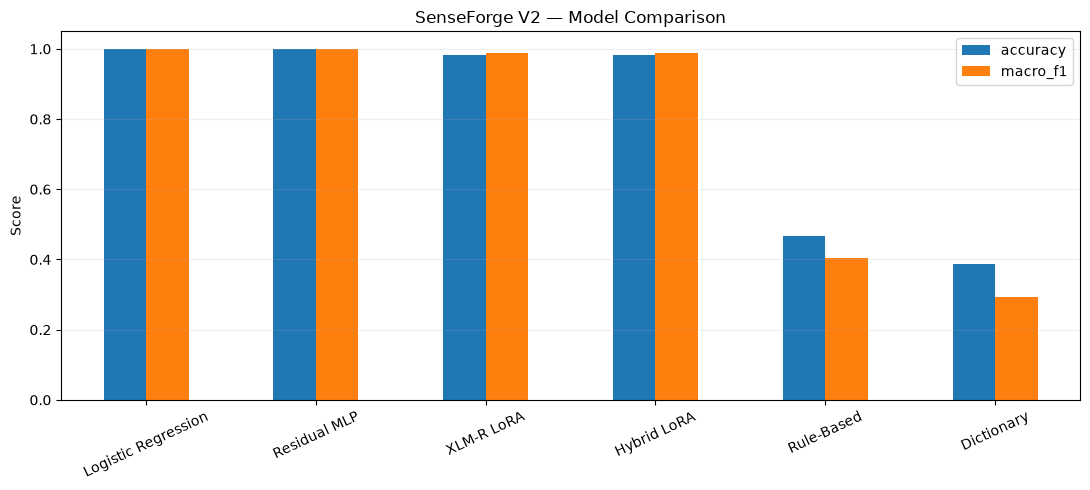


Evaluation artifacts saved: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/evaluation_v2


In [20]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Summary table
summary = pd.DataFrame.from_dict(
    comparison,
    orient="index"
).sort_values("macro_f1", ascending=False)

display(summary)

summary.to_csv(
    OUT / "model_comparison.csv"
)

# Save detailed metrics
(OUT / "model_comparison.json").write_text(
    json.dumps(comparison, indent=2),
    encoding="utf-8"
)

# Save per-model classification reports
for name, pred in all_predictions.items():
    report = classification_report(
        gold,
        pred,
        labels=SENSES,
        output_dict=True,
        zero_division=0
    )

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    (OUT / f"{filename}_report.json").write_text(
        json.dumps(report, indent=2),
        encoding="utf-8"
    )

# Plot
summary[["accuracy", "macro_f1"]].plot(
    kind="bar",
    figsize=(11, 5),
    rot=25
)

plt.title("SenseForge V2 — Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUT / "model_comparison.png",
    dpi=180
)

plt.show()

print("\nEvaluation artifacts saved:", OUT)


In [22]:
import pandas as pd

diagnostics = []

for i, row in enumerate(test_rows):
    predictions = {
        name: str(pred[i])
        for name, pred in all_predictions.items()
    }

    if (
        len(set(predictions.values())) > 1
        or predictions["XLM-R LoRA"] != row["sense_id"]
    ):
        diagnostics.append({
            "record_id": row["record_id"],
            "word": row["target_word"],
            "sentence": row["text_en"],
            "gold": row["sense_id"],
            **predictions,
            "lora_confidence": lora_confidence[i],
            "hybrid_used_neural": (
                lora_confidence[i] >= threshold
            )
        })

diagnostic_df = pd.DataFrame(diagnostics)

print("Disagreement/error examples:", len(diagnostic_df))

if not diagnostic_df.empty:
    display(diagnostic_df)

    diagnostic_df.to_csv(
        OUT / "model_disagreements.csv",
        index=False
    )

print("\nLoRA errors:", sum(
    p != g for p, g in zip(lora_pred, gold)
))

print("Hybrid errors:", sum(
    p != g for p, g in zip(hybrid_pred, gold)
))

print("Hybrid fallback count:", sum(
    c < threshold for c in lora_confidence
))

Disagreement/error examples: 38


,record_id,word,sentence,gold,Dictionary,Rule-Based,Logistic Regression,Residual MLP,XLM-R LoRA,Hybrid LoRA,lora_confidence,hybrid_used_neural
0,d117.s072.t007,bank,"Along Wappinger Creek in Dutchess County , pas...",bank.2,bank.1,bank.1,bank.2,bank.2,bank.2,bank.2,0.999892,True
1,d032.s089.t011,bank,"Through the splash of the rising waters , they...",bank.2,bank.1,bank.2,bank.2,bank.2,bank.2,bank.2,0.999667,True
2,d103.s118.t005,bank,He turned slowly and began to crawl back up th...,bank.2,bank.1,bank.1,bank.2,bank.2,bank.2,bank.2,0.998804,True
3,d000.s066.t002,plant,Too many plant officials are all too eager to ...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999877,True
4,d000.s066.t013,plant,Too many plant officials are all too eager to ...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999620,True
5,d105.s022.t011,plant,The lack of adequate data on the aerated lagoo...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999474,True
6,d000.s061.t000,plant,Can your plant nurse be replaced by a trained ...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999444,True
7,d000.s067.t002,plant,But even if that other plant employs the same ...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999965,True
8,d036.s095.t002,plant,"With greater investments in plant facilities ,...",plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999947,True
9,d024.s006.t010,plant,recommend to the Congress from time to time au...,plant.2,plant.1,plant.1,plant.2,plant.2,plant.2,plant.2,0.999983,True



LoRA errors: 1
Hybrid errors: 1
Hybrid fallback count: 1
